## Overall survival among patients with HER2-positive Breast Cancer Recieving Targeted Therapy + standared of care vs only standard of care

In [ ]:
import pandas as pd
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

In [14]:
cprd=pd.read_excel('UCL Health Data Workshop_simulated dataset exploration.xlsx',sheet_name='CPRD_Primary_Care')
sact=pd.read_excel('UCL Health Data Workshop_simulated dataset exploration.xlsx',sheet_name='SACT_Cancer_Registry')
hes=pd.read_excel('UCL Health Data Workshop_simulated dataset exploration.xlsx',sheet_name='HES_Secondary_Care')
ons=pd.read_excel('UCL Health Data Workshop_simulated dataset exploration.xlsx',sheet_name='ONS_Mortality')

# 1. Data Cleaning

In [35]:
df=pd.merge(cprd,sact,on='patid') # merge sheet cprd & sact
df=pd.merge(df,hes,on='patid') # merge hes with df
df=pd.merge(df,ons,on='patid') # merge ons with df
df=df.rename(columns={'age_at_index_x':'age'})
print(df.head())
print(df.shape)
print(df.info())

     patid   pracid  gender  year_of_birth  age  practice_region  \
0  PAT1001  PRAC108  Female           1969   53           London   
1  PAT1002  PRAC128  Female           1969   53  East of England   
2  PAT1003  PRAC115  Female           1975   47       North West   
3  PAT1004  PRAC121  Female           1969   53       South West   
4  PAT1005  PRAC106  Female           1966   56           London   

  cprd_reg_date breast_cancer_dx_date        cprd_her2_status  imd_decile  \
0    2018-11-19            2021-01-10  Missing / Not Recorded           9   
1    2020-12-20            2022-07-20  Missing / Not Recorded           9   
2    2015-07-07            2022-08-06  Missing / Not Recorded           3   
3    2020-07-27            2023-04-08  Missing / Not Recorded           4   
4    2015-01-16            2022-05-05  Missing / Not Recorded           1   

   ... secondary_cvd_comorbidity secondary_renal_comorbidity  \
0  ...                         0                           0   


In [36]:
# Check Data
print("Number of patients:", df['patid'].nunique()) #number of patients
print("Duplicates:",df['patid'].duplicated()) #check if this is any duplicate
print(df.isnull().sum()) #check if there is any missing value
print(df['systemic_regimen_arm'].value_counts()) #check treatment groups
print(df['vital_status_outcome'].value_counts()) #check survival outcomes

Number of patients: 120
Duplicates: 0      False
1      False
2      False
3      False
4      False
       ...  
115    False
116    False
117    False
118    False
119    False
Name: patid, Length: 120, dtype: bool
patid                            0
pracid                           0
gender                           0
year_of_birth                    0
age                              0
practice_region                  0
cprd_reg_date                    0
breast_cancer_dx_date            0
cprd_her2_status                 0
imd_decile                       0
smoking_status                   0
bmi                              0
charlson_comorbidity_index       0
hypertension_flag                0
diabetes_flag                    0
transfer_out_date              115
cancer_stage_at_dx               0
tumor_histology                  0
er_receptor_status               0
pr_receptor_status               0
her2_status_sact                 0
her2_mutation_variant            0
systemic_regi

In [37]:
# Choose the variables that I need
survival_df=df[['patid','age','systemic_regimen_arm','cancer_stage_at_dx','er_receptor_status','pr_receptor_status',"charlson_comorbidity_index",'overall_survival_days','death_recorded_flag','vital_status_outcome']].copy()
#survival time, event indicator, exporsure variable, confounders, biomarkers 
survival_df.head()

,patid,age,systemic_regimen_arm,cancer_stage_at_dx,er_receptor_status,pr_receptor_status,charlson_comorbidity_index,overall_survival_days,death_recorded_flag,vital_status_outcome
0,PAT1001,53,New Targeted HER2 Inhibitor + SoC,Stage II,Negative,Positive,0,1974,0,Censored (Alive at Study End)
1,PAT1002,53,New Targeted HER2 Inhibitor + SoC,Stage III,Positive,Positive,1,1388,0,Censored (Alive at Study End)
2,PAT1003,47,New Targeted HER2 Inhibitor + SoC,Stage IV,Positive,Negative,2,245,0,Censored (Transferred Practice)
3,PAT1004,53,New Targeted HER2 Inhibitor + SoC,Stage IV,Positive,Negative,2,1101,0,Censored (Alive at Study End)
4,PAT1005,56,New Targeted HER2 Inhibitor + SoC,Stage II,Positive,Positive,0,629,1,Deceased


In [60]:
#divide groups by treatments & Identify baseline imbalance
from tableone import TableOne
df['bmi']=pd.to_numeric(df['bmi'],errors="coerce") #changing missing value into NaN
columns=['age','bmi','smoking_status','imd_decile','cancer_stage_at_dx','tumor_histology','er_receptor_status','pr_receptor_status','her2_mutation_variant',"charlson_comorbidity_index",'hypertension_flag','diabetes_flag']
categorical=['smoking_status','cancer_stage_at_dx','tumor_histology','er_receptor_status','pr_receptor_status','her2_mutation_variant','hypertension_flag','diabetes_flag']
groupby='systemic_regimen_arm'
table=TableOne(df,columns=columns,categorical=categorical,groupby=groupby,pval=True,smd=True)
print(table.tabulate(tablefmt='github'))

|                                       |                             |   Missing | Overall    | New Targeted HER2 Inhibitor + SoC   |   SMD (New Targeted HER2 Inhibitor + SoC,Standard of Care Alone) | Standard of Care Alone   | P-Value   |
|---------------------------------------|-----------------------------|-----------|------------|-------------------------------------|------------------------------------------------------------------|--------------------------|-----------|
| n                                     |                             |           | 120        | 60                                  |                                                                  | 60                       |           |
| age, mean (SD)                        |                             |         0 | 58.4 (8.8) | 53.9 (6.5)                          |                                                            1.176 | 62.9 (8.6)               | <0.001    |
| bmi, mean (SD)                    

## 2. Survival Analysis

2.1 Kaplan-Meier curves

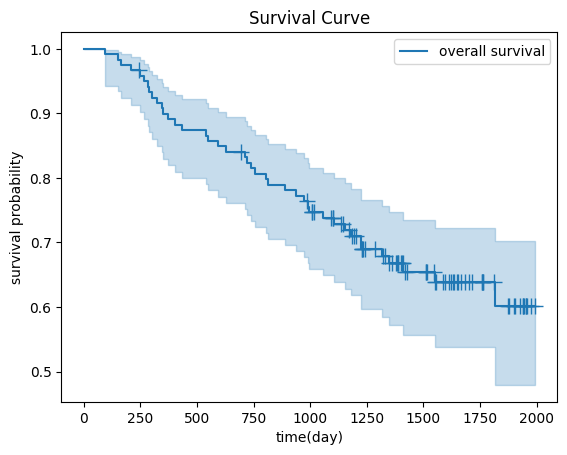

In [61]:
#Overall
from lifelines import KaplanMeierFitter
kmf=KaplanMeierFitter()
kmf.fit(durations=survival_df['overall_survival_days'],event_observed=survival_df['death_recorded_flag'],label='overall survival')
kmf.plot_survival_function(ci_show=True,show_censors=True)
plt.title("Survival Curve")
plt.xlabel('time(day)')
plt.ylabel('survival probability')
plt.show()

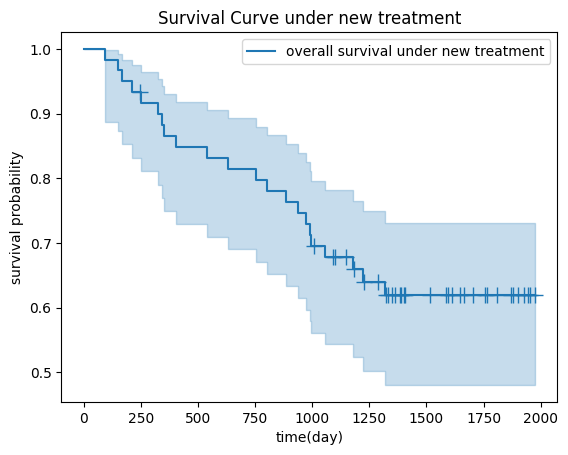

In [62]:
#Treatment group
import matplotlib.pyplot as plt
kmf_treatment=KaplanMeierFitter()
treatment=survival_df[survival_df['systemic_regimen_arm']=='New Targeted HER2 Inhibitor + SoC']
kmf_treatment.fit(durations=treatment['overall_survival_days'],event_observed=treatment['death_recorded_flag'],label='overall survival under new treatment')
kmf_treatment.plot_survival_function(ci_show=True,show_censors=True)
plt.title("Survival Curve under new treatment")
plt.xlabel('time(day)')
plt.ylabel('survival probability')
plt.show()

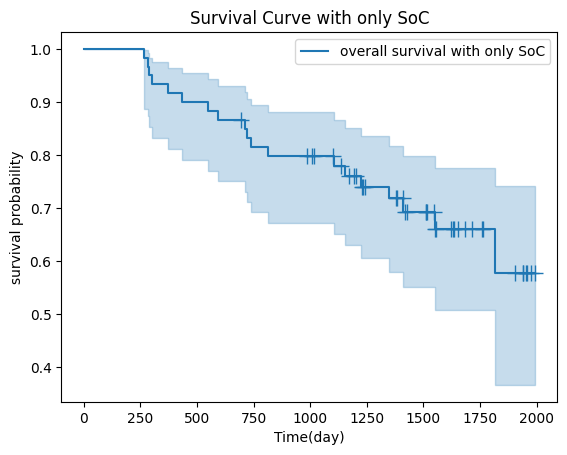

In [63]:
#control group
kmf_control=KaplanMeierFitter()
control=survival_df[survival_df['systemic_regimen_arm']=="Standard of Care Alone"]
kmf_control.fit(durations=control['overall_survival_days'],event_observed=control['death_recorded_flag'],label='overall survival with only SoC')
kmf_control.plot_survival_function(ci_show=True,show_censors=True)
plt.title("Survival Curve with only SoC")
plt.xlabel("Time(day)")
plt.ylabel("survival probability")
plt.show()

In [64]:
#Log_rank test
from lifelines.statistics import logrank_test
results=logrank_test(treatment['overall_survival_days'],control['overall_survival_days'],event_observed_A=treatment['death_recorded_flag'],event_observed_B=control['death_recorded_flag'])
print('Log_rank p value:',results.p_value)

Log_rank p value: 0.48876309514622984


2.2 Cox proportional hazards model

In [ ]:
from lifelines import CoxPHFitter
cox_df=survival_df.copy()
cox_df=cox_df[['overall_survival_days','death_recorded_flag','systemic_regimen_arm','age','cancer_stage_at_dx','charlson_comorbidity_index']]
cox_df=pd.get_dummies(cox_df,columns=['systemic_regimen_arm','cancer_stage_at_dx'],drop_first=True,dtype=int) #compare treatment groups directly
cph=CoxPHFitter()
cph.fit(cox_df,duration_col='overall_survival_days',event_col='death_recorded_flag')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 120 total observations, 79 right-censored observations>
             duration col = 'overall_survival_days'
                event col = 'death_recorded_flag'
      baseline estimation = breslow
   number of observations = 120
number of events observed = 41
   partial log-likelihood = -176.54
         time fit was run = 2026-11-20 17:24:29 UTC

---
                                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                    
age                                         -0.02      0.98      0.03           -0.07            0.04                0.93                1.04
charlson_comorbidity_index                  -0.06      0.94      0.23           -0.51            0.39                0.60                1.47
systemic_regimen_arm_Standard of Care Alone  0.38      1.46      0.37           -0.34            1.10                0.71                2.99
cancer_stage_at_dx_Stage II                  0.07      1.07      0.68           -1.27            1.41                0.28                4.09
cancer_stage_at_dx_Stage III                 1.07      2.90      0.68           -0.26            2.39                0.77               10.92
cancer_stage_at_dx_Stage IV                  1.70      5.46      0.88           -0.03            3.43                0.97               30.86

                                             cmp to     z    p  -log2(p)
covariate                                                               
age                                            0.00 -0.61 0.54      0.89
charlson_comorbidity_index                     0.00 -0.26 0.79      0.34
systemic_regimen_arm_Standard of Care Alone    0.00  1.04 0.30      1.74
cancer_stage_at_dx_Stage II                    0.00  0.10 0.92      0.12
cancer_stage_at_dx_Stage III                   0.00  1.58 0.11      3.12
cancer_stage_at_dx_Stage IV                    0.00  1.92 0.05      4.19
---
Concordance = 0.66
Partial AIC = 365.07
log-likelihood ratio test = 14.89 on 6 df
-log2(p) of ll-ratio test = 5.56


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

Proportional hazard assumption looks okay.


[[<Axes: xlabel='rank-transformed time\n(p=0.6485)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5941)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0932)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0633)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.4022)'>,
  <Axes: xlabel='km-transformed time\n(p=0.3416)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7540)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7281)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8254)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8713)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.5368)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5175)'>]]

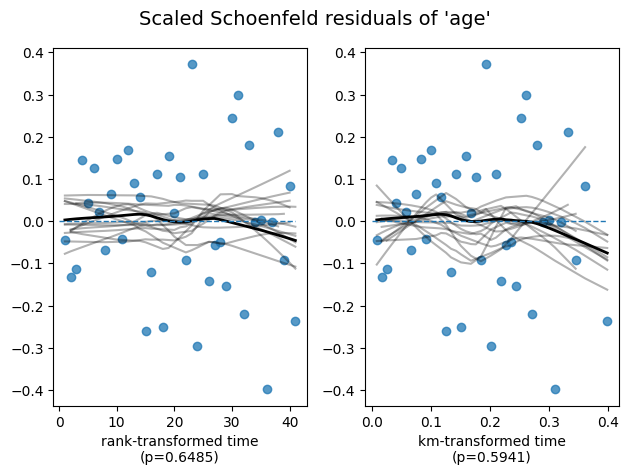

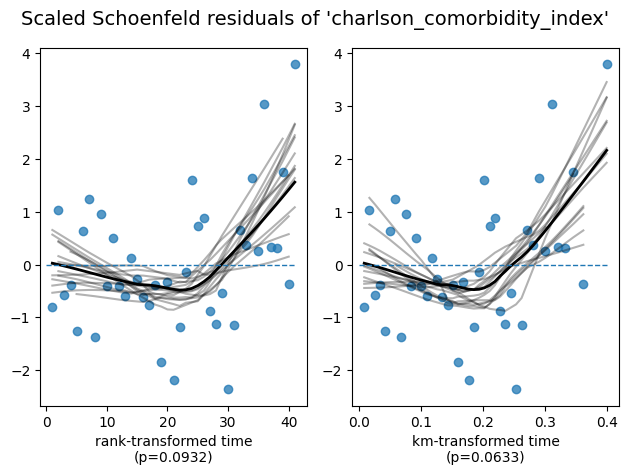

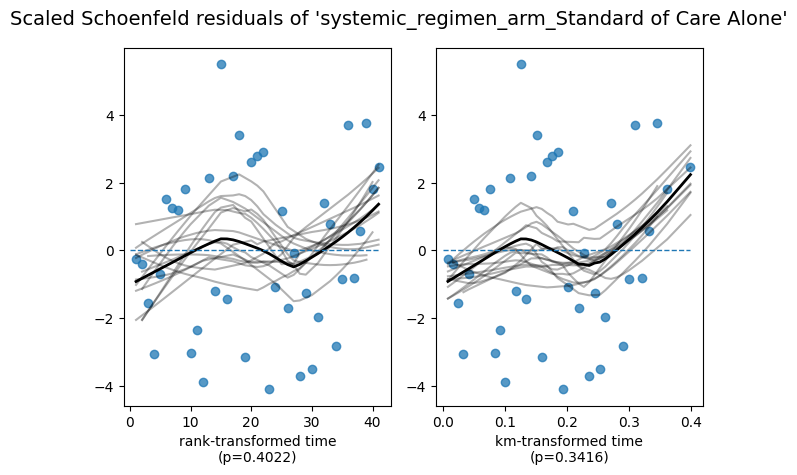

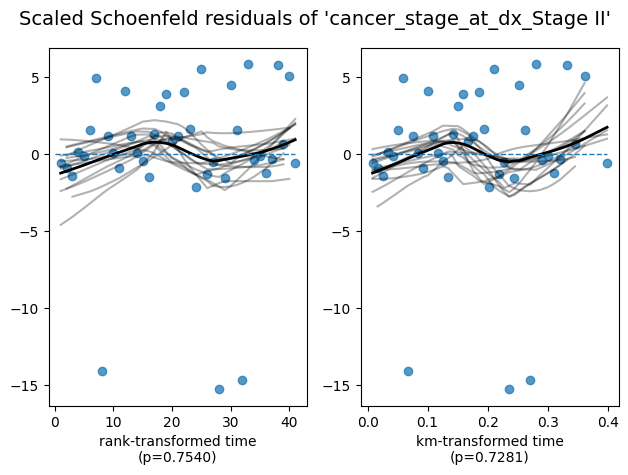

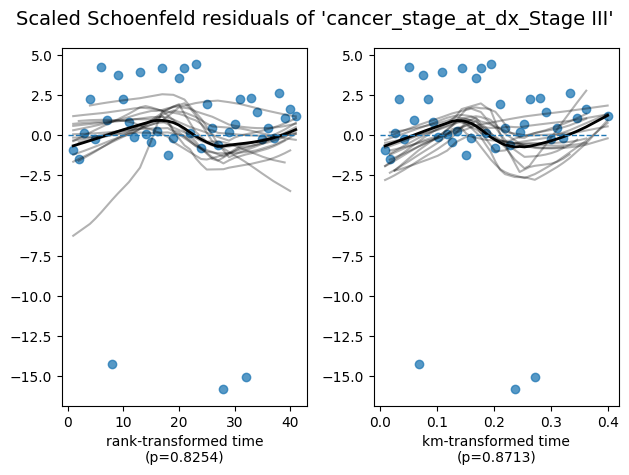

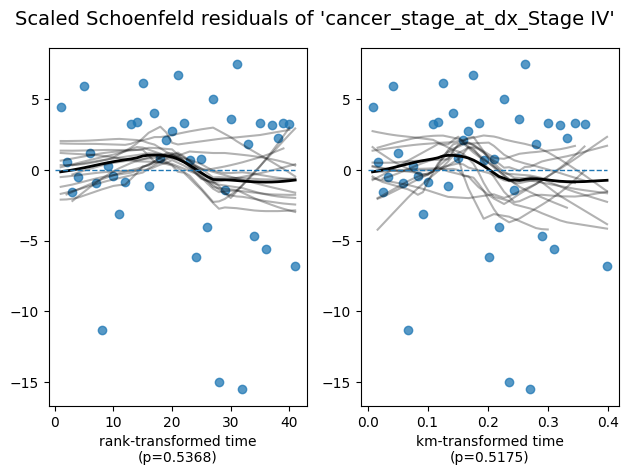

In [66]:
#check model assumption
cph.check_assumptions(cox_df,p_value_threshold=0.05,show_plots=True)